# GPE real-time GPU benchmark

Use a **fresh Colab GPU runtime** and run the cells in order. This loads a saved
imaginary-time state and evolves it with the existing `ssfmstep` at its saved grid
size: **200 steps**, with 5 warm-up and 5 profiled steps. All steps advance the state.

The saved box trap and beta are restored. Absorption is disabled, so the norm should
remain constant without renormalisation. `dt=0.01` is explicit and adjustable;
this benchmark does not establish timestep accuracy or ground-state convergence.

At **1024³**, the current complex128 solver uses about **64 GiB** for its main arrays,
plus FFT workspace. The preflight reserves an estimated additional 8 GiB. An
**80 GB GPU** is the intended target; the notebook never lowers the grid size.

Set `source_run` below to the saved run you want. Its `psi_final.npy` (16 GiB),
`psi_final_grid.npz`, and `run_metadata.json` must have finished copying to Drive.
The input is copied to local disk and loaded in slabs to limit CPU memory use.

Timing CSVs and metadata are saved to a new `benchmark_results/realtime` folder.
Set `save_final_state=True` to also save the evolved wavefunction.

In [1]:
import importlib.util
import subprocess
import sys

subprocess.run(["nvidia-smi"],check=True)
if importlib.util.find_spec("cupy") is None:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","cupy-cuda12x[ctk]"])

import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import shutil
import time

cp.cuda.Device(0).use()
properties=cp.cuda.runtime.getDeviceProperties(0)
gpu_name=properties['name']
if isinstance(gpu_name,bytes):
    gpu_name=gpu_name.decode()
print(f"GPU: {gpu_name} | CuPy: {cp.__version__}")
print(f"CUDA runtime: {cp.cuda.runtime.runtimeGetVersion()} | driver: {cp.cuda.runtime.driverGetVersion()}")

GPU: NVIDIA A100-SXM4-80GB | CuPy: 14.0.1
CUDA runtime: 13000 | driver: 13000


## Load the current solver

Let Drive finish syncing the `gpe` source first. Restart the runtime before
rerunning this notebook after source changes, so imports use the updated code.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT=Path("/content/drive/MyDrive/GPE_simulator")
LOCAL_PROJECT=Path("/content/GPE_simulator")
shutil.copytree(DRIVE_PROJECT/"gpe",LOCAL_PROJECT/"gpe",dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("__pycache__"))
sys.path.insert(0,str(LOCAL_PROJECT))

from gpe.grids import get_grids
from gpe.potentials import box_potential
from gpe.propagation import ssfmstep
from gpe.kernels import static_real_halfstep, kinetic_full_step
from gpe.helper import get_N, is_due
from gpe.monitor import monitor
from gpe.export import export

print(f"Loaded source from {LOCAL_PROJECT/'gpe'}")

Mounted at /content/drive
Loaded source from /content/GPE_simulator/gpe


## Run settings

The selected source defaults to the 10 October preparation. If its state is still
copying, wait for the save cell to finish or explicitly choose a completed run.
Grid size, axes, beta, and trap parameters come from the saved files.

Scalars are N (norm), E_kin (kinetic energy), and Lz. Kinetic energy alone need not
remain constant during real-time evolution. Set a monitor interval to 0 to disable it.

In [3]:
source_run="20261010T095235Z_N1024"
dt=0.01
total_steps=200
warmup_steps=5
profile_steps=5
progress_interval=10
fft_headroom_gib=8
norm_tolerance=1e-8
save_final_state=False

monitor_intervals=dict(
    print_scalar_interval=50,
    show_nk_interval=200,
    show_TOF_image_interval=200,
    show_verticle_TOF_interval=0,
    show_TOF_slice_interval=0,
    show_verticle_TOF_slice_interval=0,
    show_magnifier_interval=0,
    show_magnifier_slice_interval=200,
    show_phase_interval=0,
)

assert dt>0
assert 0<=warmup_steps and 0<profile_steps and warmup_steps+profile_steps<total_steps
SOURCE_RUN=DRIVE_PROJECT/"benchmark_results"/source_run
required_files=("psi_final.npy","psi_final_grid.npz","run_metadata.json")
missing=[name for name in required_files if not (SOURCE_RUN/name).is_file()]
if missing:
    complete=[p.name for p in sorted((DRIVE_PROJECT/"benchmark_results").iterdir())
              if p.is_dir() and all((p/name).is_file() for name in required_files)]
    raise FileNotFoundError(
        f"{SOURCE_RUN}: missing {missing}. Finish copying the saved run to Drive "
        f"or change source_run. Runs with all three files present: {complete}")

In [4]:
source_metadata_bytes=(SOURCE_RUN/"run_metadata.json").read_bytes()
source_grid_bytes=(SOURCE_RUN/"psi_final_grid.npz").read_bytes()
source_metadata=json.loads(source_metadata_bytes)
N_grids=int(source_metadata['N_grids'])
beta=float(source_metadata['beta'])
simulation_range=float(source_metadata['simulation_range'])
R,L=source_metadata['R'],source_metadata['L']
wallthickness,U_D=source_metadata['wallthickness'],source_metadata['U_D']

with np.load(SOURCE_RUN/"psi_final_grid.npz",allow_pickle=False) as saved_grid:
    x_host=saved_grid['x_array'].copy()
    k_host=saved_grid['k_array'].copy()
    saved_N=float(saved_grid['N'])
    source_step=int(saved_grid['i'])

assert x_host.shape==k_host.shape==(N_grids,)
assert x_host.dtype==k_host.dtype==np.float64
assert np.isfinite(saved_N) and saved_N>0
np.testing.assert_allclose(np.diff(x_host),simulation_range/N_grids,rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(k_host,2*np.pi*np.fft.fftfreq(N_grids,simulation_range/N_grids),
                           rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(saved_N,source_metadata['final_norm'],rtol=1e-10,atol=0)
assert source_step==source_metadata['completed_steps']

run_id=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")+f"_N{N_grids}"
LOCAL_RUN=Path("/content/gpe_realtime_benchmarks")/run_id
DRIVE_RUN=DRIVE_PROJECT/"benchmark_results"/"realtime"/run_id
LOCAL_INPUT=LOCAL_RUN/"input"
print(f"Input: {SOURCE_RUN}")
print(f"N={N_grids}, steps={total_steps}, dt={dt}, real-time duration={total_steps*dt:g}")
print(f"beta={beta:.8g}; saved norm={saved_N:.12g}; absorption disabled")
print(f"Results: {DRIVE_RUN}")

Input: /content/drive/MyDrive/GPE_simulator/benchmark_results/20261010T095235Z_N1024
N=1024, steps=200, dt=0.01, real-time duration=2
beta=59848.533; saved norm=1; absorption disabled
Results: /content/drive/MyDrive/GPE_simulator/benchmark_results/realtime/20261010T101534500751Z_N1024


In [5]:
GiB=1024**3
state_bytes=N_grids**3*np.dtype(np.complex128).itemsize
array_bytes=4*state_bytes  # Three wavefunction buffers and one complex potential.
estimated_bytes=array_bytes+fft_headroom_gib*GiB
free_bytes,total_bytes=cp.cuda.runtime.memGetInfo()
print(f"GPU free / total: {free_bytes/GiB:.2f} / {total_bytes/GiB:.2f} GiB")
print(f"Main arrays: {array_bytes/GiB:.2f} GiB; with estimated FFT reserve: {estimated_bytes/GiB:.2f} GiB")
if free_bytes<estimated_bytes:
    raise MemoryError(
        f"N={N_grids} needs an estimated {estimated_bytes/GiB:.1f} GiB, "
        f"but only {free_bytes/GiB:.1f} GiB is free. Use a fresh runtime with more GPU memory.")
if (SOURCE_RUN/"psi_final.npy").stat().st_size<state_bytes:
    raise OSError("The input wavefunction is incomplete; finish copying it to Drive first.")
disk_required=(1+int(save_final_state))*state_bytes+GiB
if shutil.disk_usage("/content").free<disk_required:
    raise OSError(f"Need about {disk_required/GiB:.1f} GiB free on local disk for this run.")

GPU free / total: 78.83 / 79.25 GiB
Main arrays: 64.00 GiB; with estimated FFT reserve: 72.00 GiB


## Check the step and set up timing

A small random 16³ state is evolved by one step and compared with an independent
NumPy split-step calculation. This checks both the production and profiling wrappers,
and compares the norm with a CPU sum before loading the large state.

The profiling wrapper mirrors `ssfmstep`. It has five stages and no normalisation.
CUDA events measure GPU time; monitoring, input loading, and saving are timed separately.
See [CuPy timing guidance](https://docs.cupy.dev/en/stable/user_guide/performance.html#benchmarking).

In [6]:
stage_names=("local_1_ms","fft_ms","kinetic_ms","ifft_ms","local_2_ms")
profile_events=[cp.cuda.Event() for _ in range(6)]
step_start,step_end=cp.cuda.Event(),cp.cuda.Event()

def profiled_real_step(psi,V_static,beta,k_array,dt,N_grids):
    grid=((psi.size+255)//256,)
    block=(256,)
    events=profile_events
    events[0].record()
    static_real_halfstep(grid,block,(psi,V_static,float(beta),float(dt),int(N_grids)))
    events[1].record()
    psi_k=cp.fft.fftn(psi)
    events[2].record()
    kinetic_full_step(grid,block,(psi_k,k_array,float(dt),int(N_grids)))
    events[3].record()
    psi=cp.fft.ifftn(psi_k)
    events[4].record()
    static_real_halfstep(grid,block,(psi,V_static,float(beta),float(dt),int(N_grids)))
    events[5].record()
    events[5].synchronize()
    stages={name:cp.cuda.get_elapsed_time(events[j],events[j+1])
            for j,name in enumerate(stage_names)}
    return psi,stages,cp.cuda.get_elapsed_time(events[0],events[5])


def check_small_step():
    n,length=16,2*np.pi
    x,k=get_grids(n,length)
    xc,kc=cp.asnumpy(x),cp.asnumpy(k)
    dx=length/n
    rng=np.random.default_rng(42)
    state=rng.normal(size=(n,n,n))+1j*rng.normal(size=(n,n,n))
    state/=np.sqrt(np.sum(abs(state)**2)*dx**3)
    potential=(0.3*np.cos(xc[:,None,None])+0.2*np.sin(xc[None,:,None])
               +0.1*np.cos(xc[None,None,:]))
    expected=state*np.exp(-0.5j*dt*(potential+beta*abs(state)**2))
    k2=kc[:,None,None]**2+kc[None,:,None]**2+kc[None,None,:]**2
    expected=np.fft.ifftn(np.fft.fftn(expected)*np.exp(-1j*dt*k2))
    expected*=np.exp(-0.5j*dt*(potential+beta*abs(expected)**2))

    psi_small=cp.asarray(state)
    V_small=cp.asarray(potential,dtype=cp.complex128)
    production=ssfmstep(psi_small.copy(),V_small,beta,k,dt,n)
    profiled,_,_=profiled_real_step(psi_small.copy(),V_small,beta,k,dt,n)
    for result in (production,profiled):
        on_cpu=cp.asnumpy(result)
        np.testing.assert_allclose(on_cpu,expected,rtol=1e-10,atol=1e-12)
        cpu_norm=np.sum(abs(on_cpu)**2)*dx**3
        np.testing.assert_allclose(cpu_norm,1,rtol=1e-11,atol=0)
        np.testing.assert_allclose(float(get_N(result,x)),cpu_norm,rtol=1e-12,atol=0)
    cp.cuda.get_current_stream().synchronize()

check_small_step()
cp.fft.config.get_plan_cache().clear()
cp.get_default_memory_pool().free_all_blocks()
print("Small GPU step matches NumPy; production/profiled steps and norm checks passed.")

Small GPU step matches NumPy; production/profiled steps and norm checks passed.


## Load the prepared state

The 16 GiB input copy can take several minutes. Its time is excluded from the
evolution benchmark. Only the evolving state is kept on the GPU; the saved input
remains available on disk.

In [7]:
LOCAL_INPUT.mkdir(parents=True,exist_ok=True)
copy_start=time.perf_counter()
print("Copying saved wavefunction to Colab local disk...",flush=True)
shutil.copy2(SOURCE_RUN/"psi_final.npy",LOCAL_INPUT/"psi_final.npy")
(LOCAL_INPUT/"psi_final_grid.npz").write_bytes(source_grid_bytes)
(LOCAL_INPUT/"run_metadata.json").write_bytes(source_metadata_bytes)
input_copy_s=time.perf_counter()-copy_start
print(f"Input copy: {input_copy_s:.2f} s. Loading GPU state...",flush=True)

setup_start=time.perf_counter()
saved=np.load(LOCAL_INPUT/"psi_final.npy",mmap_mode="r",allow_pickle=False)
assert saved.shape==(N_grids,N_grids,N_grids) and saved.dtype==np.complex128
assert saved.flags.c_contiguous
psi=cp.empty(saved.shape,dtype=cp.complex128)
for start in range(0,N_grids,16):
    psi[start:start+16].set(np.asarray(saved[start:start+16]))
cp.cuda.get_current_stream().synchronize()
del saved
x_array=cp.asarray(x_host)
k_array=cp.asarray(k_host)
box=box_potential(x_array,R,L,wallthickness,U_D)
V_static=box.astype(cp.complex128)
del box
initial_N=float(get_N(psi,x_array))
np.testing.assert_allclose(initial_N,saved_N,rtol=1e-10,atol=0)
cp.cuda.get_current_stream().synchronize()
cp.get_default_memory_pool().free_all_blocks()
gpu_setup_s=time.perf_counter()-setup_start
print(f"GPU setup: {gpu_setup_s:.2f} s; loaded norm={initial_N:.12g}")

Copying saved wavefunction to Colab local disk...
Input copy: 211.85 s. Loading GPU state...
GPU setup: 6.01 s; loaded norm=1


## Evolve and benchmark

Run this cell once per loaded state. To repeat from the same input, rerun the
load-state cell first. Warm-up and profiled steps count toward the total evolution
but are excluded from the ordinary-step timing summary.

10/200: 240.40 ms/step, GPU used 64.43 GiB
20/200: 240.54 ms/step, GPU used 64.43 GiB
30/200: 240.50 ms/step, GPU used 64.43 GiB
40/200: 240.52 ms/step, GPU used 64.43 GiB
i=50  N=1  E_kin=0.068370918  Lz=-1.3550975e-20
50/200: 240.21 ms/step, GPU used 64.43 GiB
60/200: 240.35 ms/step, GPU used 64.43 GiB
70/200: 241.01 ms/step, GPU used 64.43 GiB
80/200: 240.65 ms/step, GPU used 64.43 GiB
90/200: 240.89 ms/step, GPU used 64.43 GiB
i=100  N=1  E_kin=0.085637985  Lz=1.0140466e-19
100/200: 240.63 ms/step, GPU used 64.43 GiB
110/200: 240.69 ms/step, GPU used 64.43 GiB
120/200: 240.84 ms/step, GPU used 64.43 GiB
130/200: 240.85 ms/step, GPU used 64.43 GiB
140/200: 240.97 ms/step, GPU used 64.43 GiB
i=150  N=1  E_kin=0.10374684  Lz=-4.6115008e-20
150/200: 241.34 ms/step, GPU used 64.43 GiB
160/200: 241.14 ms/step, GPU used 64.43 GiB
170/200: 241.12 ms/step, GPU used 64.43 GiB
180/200: 241.24 ms/step, GPU used 64.43 GiB
190/200: 241.13 ms/step, GPU used 64.43 GiB
i=200  N=1  E_kin=0.11938809 

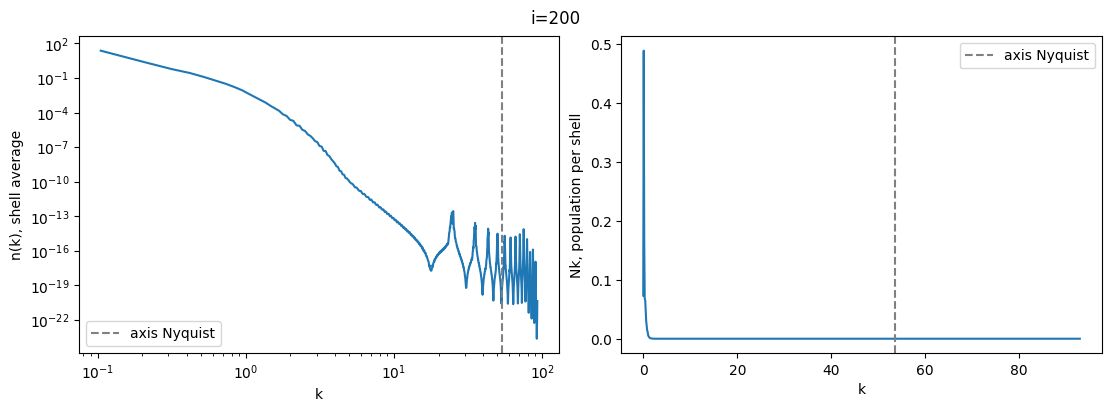

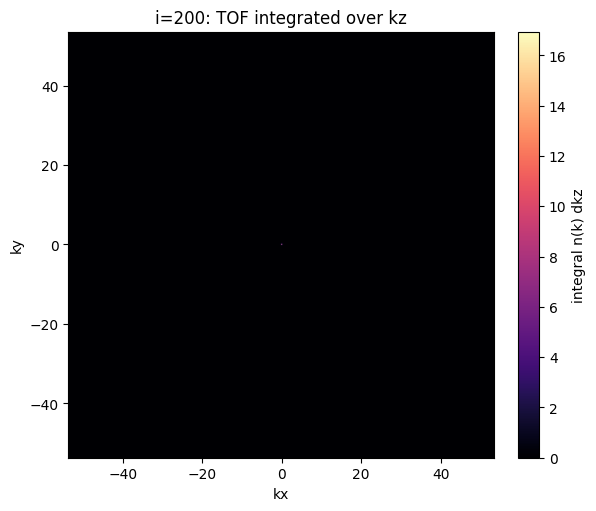

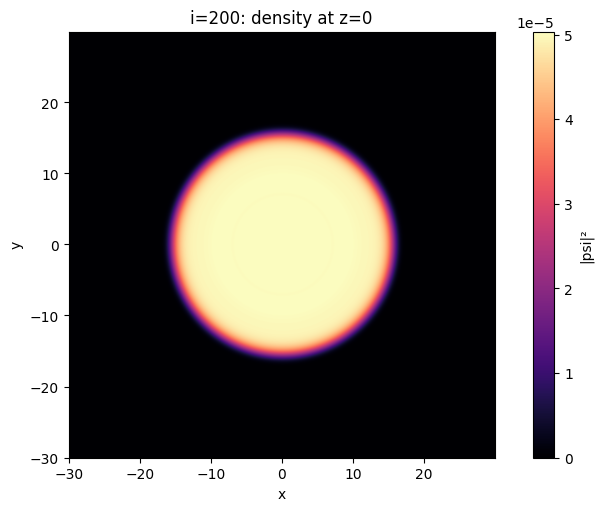

200/200: 240.72 ms/step, GPU used 64.43 GiB
Finished 200 steps in 73.98 s; real time=2
Norm: 1 -> 1; relative drift=+6.417e-14
Norm check: PASS (tolerance 1e-08)


In [8]:
rows=[]
scalar_rows=[]
completed_steps=0
run_start=time.perf_counter()
for i in range(1,total_steps+1):
    wall_start=time.perf_counter()
    stages={}
    if warmup_steps<i<=warmup_steps+profile_steps:
        mode="profiled"
        psi,stages,gpu_ms=profiled_real_step(psi,V_static,beta,k_array,dt,N_grids)
    else:
        mode="warmup" if i<=warmup_steps else "normal"
        step_start.record()
        psi=ssfmstep(psi,V_static,beta,k_array,dt,N_grids)
        step_end.record()
        step_end.synchronize()
        gpu_ms=cp.cuda.get_elapsed_time(step_start,step_end)
    step_wall_ms=1000*(time.perf_counter()-wall_start)
    completed_steps=i

    monitor_s=0.0
    if any(is_due(i,interval) for interval in monitor_intervals.values()):
        monitor_start=time.perf_counter()
        values=monitor(i,psi,k_array,x_array,**monitor_intervals)
        cp.cuda.get_current_stream().synchronize()
        monitor_s=time.perf_counter()-monitor_start
        if 'N' in values:
            scalar_rows.append(dict(i=i,t=i*dt,N=values['N'],E_kin=values['E'],Lz=values['L'],
                                    relative_norm_drift=values['N']/initial_N-1))

    free_now,total_now=cp.cuda.runtime.memGetInfo()
    rows.append(dict(i=i,t=i*dt,mode=mode,gpu_ms=gpu_ms,step_wall_ms=step_wall_ms,
                     monitor_s=monitor_s,gpu_used_gib=(total_now-free_now)/GiB,
                     pool_reserved_gib=cp.get_default_memory_pool().total_bytes()/GiB,**stages))
    if i%progress_interval==0 or i==total_steps:
        print(f"{i}/{total_steps}: {gpu_ms:.2f} ms/step, GPU used {(total_now-free_now)/GiB:.2f} GiB",flush=True)

run_wall_s=time.perf_counter()-run_start
final_N=float(get_N(psi,x_array))
relative_norm_drift=final_N/initial_N-1
sampled_norm_drifts=[relative_norm_drift,*[r['relative_norm_drift'] for r in scalar_rows]]
norm_check_passed=all(np.isfinite(d) and abs(d)<=norm_tolerance for d in sampled_norm_drifts)
print(f"Finished {completed_steps} steps in {run_wall_s:.2f} s; real time={completed_steps*dt:g}")
print(f"Norm: {initial_N:.12g} -> {final_N:.12g}; relative drift={relative_norm_drift:+.3e}")
print(f"Norm check: {'PASS' if norm_check_passed else 'FAIL'} (tolerance {norm_tolerance:g})")

Ordinary steps: median 241.12 ms, mean 241.19 ms, p95 241.98 ms
Monitoring: 25.59 s total; input loading and saving are separate.
local_1_ms           28.643 ms  ( 11.9% of profiled stages)
fft_ms               71.400 ms  ( 29.7% of profiled stages)
kinetic_ms           19.976 ms  (  8.3% of profiled stages)
ifft_ms              92.129 ms  ( 38.3% of profiled stages)
local_2_ms           28.575 ms  ( 11.9% of profiled stages)


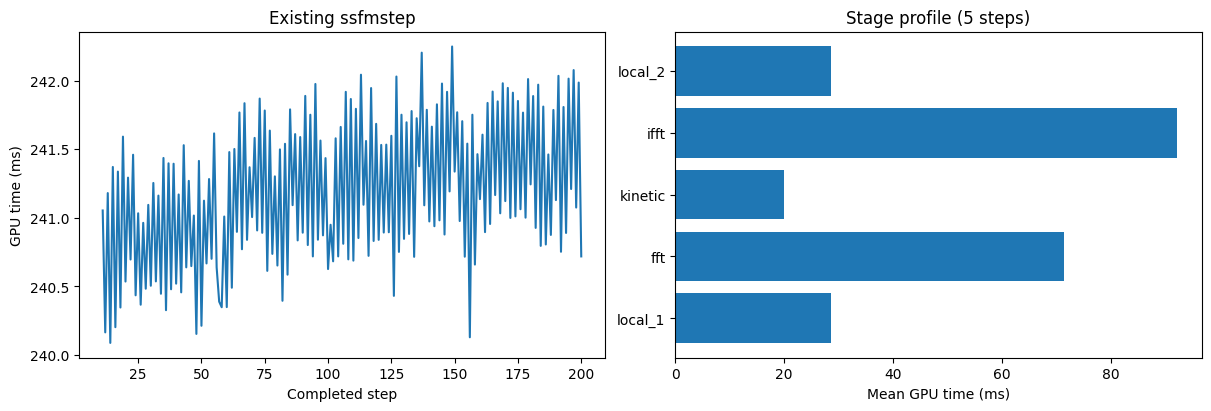

In [9]:
normal_rows=[row for row in rows if row['mode']=="normal"]
gpu_times=np.array([row['gpu_ms'] for row in normal_rows])
wall_times=np.array([row['step_wall_ms'] for row in normal_rows])
profile_rows=[row for row in rows if row['mode']=="profiled"]
stage_means={name:float(np.mean([row[name] for row in profile_rows])) for name in stage_names}
summary=dict(
    measured_steps=len(normal_rows),
    mean_gpu_ms=float(gpu_times.mean()),median_gpu_ms=float(np.median(gpu_times)),
    p95_gpu_ms=float(np.percentile(gpu_times,95)),mean_step_wall_ms=float(wall_times.mean()),
    evolution_wall_s=run_wall_s,monitor_wall_s=sum(row['monitor_s'] for row in rows),
    input_copy_s=input_copy_s,gpu_setup_s=gpu_setup_s,
    max_observed_gpu_used_gib=max(row['gpu_used_gib'] for row in rows),
    max_observed_pool_reserved_gib=max(row['pool_reserved_gib'] for row in rows),
    profiled_stage_means_ms=stage_means,
    initial_norm=initial_N,final_norm=final_N,relative_norm_drift=relative_norm_drift,
    max_sampled_relative_norm_drift=max(abs(d) for d in sampled_norm_drifts),
    norm_check_passed=bool(norm_check_passed),
)
print(f"Ordinary steps: median {summary['median_gpu_ms']:.2f} ms, mean {summary['mean_gpu_ms']:.2f} ms, p95 {summary['p95_gpu_ms']:.2f} ms")
print(f"Monitoring: {summary['monitor_wall_s']:.2f} s total; input loading and saving are separate.")
for name,value in stage_means.items():
    print(f"{name:16s} {value:10.3f} ms  ({100*value/sum(stage_means.values()):5.1f}% of profiled stages)")

fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
axes[0].plot([row['i'] for row in normal_rows],gpu_times)
axes[0].set(xlabel="Completed step",ylabel="GPU time (ms)",title="Existing ssfmstep")
axes[1].barh([name.removesuffix('_ms') for name in stage_names],list(stage_means.values()))
axes[1].set(xlabel="Mean GPU time (ms)",title=f"Stage profile ({profile_steps} steps)")
plt.show()
plt.close(fig)

## Save benchmark results

This writes step timings, scalar history, and metadata, including input provenance
and hashes of the solver source. Results go into a new real-time run folder.
If enabled in settings, the evolved state is also saved in slabs as `psi_final.npy`.
This optional 16 GiB write and Drive copy are outside the evolution timings.

In [10]:
if completed_steps!=total_steps:
    raise RuntimeError("Finish the evolution cell before saving the benchmark results.")
LOCAL_RUN.mkdir(parents=True,exist_ok=True)
result_files=[]
summary['final_save_local_s']=0.0
if save_final_state:
    if not norm_check_passed:
        raise RuntimeError("Norm check failed; inspect the run before saving an evolved state.")
    save_start=time.perf_counter()
    export(completed_steps,psi,k_array,x_array,psi_interval=completed_steps,
           nk_interval=0,N_interval=0,output_dir=LOCAL_RUN)
    (LOCAL_RUN/f"psi_{completed_steps:08d}.npy").replace(LOCAL_RUN/"psi_final.npy")
    (LOCAL_RUN/f"psi_{completed_steps:08d}_grid.npz").replace(LOCAL_RUN/"psi_final_grid.npz")
    summary['final_save_local_s']=time.perf_counter()-save_start
    result_files.extend(["psi_final.npy","psi_final_grid.npz"])

with (LOCAL_RUN/"step_timings.csv").open("w",newline="") as file:
    fields=["i","t","mode","gpu_ms","step_wall_ms","monitor_s","gpu_used_gib","pool_reserved_gib",*stage_names]
    writer=csv.DictWriter(file,fieldnames=fields)
    writer.writeheader()
    writer.writerows(rows)
with (LOCAL_RUN/"monitor_scalars.csv").open("w",newline="") as file:
    writer=csv.DictWriter(file,fieldnames=["i","t","N","E_kin","Lz","relative_norm_drift"])
    writer.writeheader()
    writer.writerows(scalar_rows)

metadata=dict(
    run_id=run_id,evolution="real_time",integrator="ssfmstep",gpu=gpu_name,
    cupy=cp.__version__,numpy=np.__version__,python=sys.version,
    cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),cuda_driver=cp.cuda.runtime.driverGetVersion(),
    source_run=str(SOURCE_RUN),source_step=source_step,source_state="psi_final.npy",
    source_metadata_sha256=hashlib.sha256(source_metadata_bytes).hexdigest(),
    source_grid_sha256=hashlib.sha256(source_grid_bytes).hexdigest(),
    source_metadata=source_metadata,
    N_grids=N_grids,simulation_range=simulation_range,R=R,L=L,wallthickness=wallthickness,
    U_D=U_D,beta=beta,dt=dt,dtype=str(psi.dtype),absorption=False,
    completed_steps=completed_steps,real_time=completed_steps*dt,final_norm=final_N,
    warmup_steps=warmup_steps,profile_steps=profile_steps,monitor_intervals=monitor_intervals,
    norm_tolerance=norm_tolerance,save_final_state=save_final_state,
    source_sha256={path.name:hashlib.sha256(path.read_bytes()).hexdigest()
                   for path in sorted((LOCAL_PROJECT/"gpe").iterdir()) if path.suffix in (".py",".cuh")},
    benchmark=summary,
)
(LOCAL_RUN/"run_metadata.json").write_text(json.dumps(metadata,indent=2)+"\n")
result_files.extend(["step_timings.csv","monitor_scalars.csv","run_metadata.json"])

DRIVE_RUN.mkdir(parents=True,exist_ok=True)
copy_start=time.perf_counter()
print("Copying benchmark results to Drive...",flush=True)
for name in result_files:
    shutil.copy2(LOCAL_RUN/name,DRIVE_RUN/name)
print(f"Drive result copy: {time.perf_counter()-copy_start:.2f} s")
print(f"Saved results: {DRIVE_RUN}")

Copying benchmark results to Drive...
Drive result copy: 0.02 s
Saved results: /content/drive/MyDrive/GPE_simulator/benchmark_results/realtime/20261010T101534500751Z_N1024
